# 05 · Strategy simulator

Using each race's fitted tyre model (notebook 02) and its measured pit loss, enumerate every
1-stop and 2-stop plan:

* use at least two different dry compounds;
* no stint shorter than 5 laps;
* no stint longer than the longest one actually run on that compound in that race (+3 laps).

Total race time = Σ (base lap + compound offset + slope × tyre age) + stops × pit loss. Fuel
and track evolution are identical for every plan, so they don't change the ranking.

The simulator plans a race **before the start**. It knows nothing about safety cars, which
often decide real strategies, so we compare it with what the winners actually did and look at
where it differs.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from f1tyres import plots
from f1tyres.analysis import (
    best_by_stops,
    clean_laps,
    fit_race_tyre_model,
    observed_max_stint,
    simulate_strategies,
    stints,
    strategy_review,
)
from f1tyres.config import DATA_PROCESSED
from f1tyres.data import load_tables

plots.apply_style()
t = load_tables()
laps, results = t["laps"], t["results"]
pl = pd.read_parquet(DATA_PROCESSED / "pit_loss.parquet")

review = strategy_review(laps, results, pl)
review.to_parquet(DATA_PROCESSED / "strategy_review.parquet", index=False)
print(f"{len(review)} dry races simulated")
review[["Season", "EventName", "PitLoss", "BestPlan", "BestPitLaps", "OneStopVsTwoStop",
        "WinnerPlan", "Neutralised"]].head(12).round(1)

77 dry races simulated


,Season,EventName,PitLoss,BestPlan,BestPitLaps,OneStopVsTwoStop,WinnerPlan,Neutralised
0,2022,Bahrain Grand Prix,24.5,M-S-S,"[19, 38]",NaN,S-S-M-S,True
1,2022,Saudi Arabian Grand Prix,23.8,H-M,[42],-21.9,M-H,True
2,2022,Australian Grand Prix,22.7,H-M,[50],-21.6,M-H,True
3,2022,Miami Grand Prix,21.9,H-M,[45],-20.0,M-H,True
4,2022,Spanish Grand Prix,22.7,M-S-S,"[21, 43]",NaN,S-M-S-M,False
5,2022,Azerbaijan Grand Prix,25.8,H-M,[33],-14.0,M-H-H,True
6,2022,Canadian Grand Prix,19.4,H-M,[38],-7.3,M-H-H,True
7,2022,British Grand Prix,22.8,H-S,[28],-16.1,M-M-H-S,True
8,2022,French Grand Prix,29.3,H-M,[26],-10.6,M-H,True
9,2022,Hungarian Grand Prix,23.4,M-M-S,"[26, 52]",9.3,S-M-M,True


## Does the optimum match what winners did?

In [2]:
review["Match"] = review["BestStops"] == review["WinnerStops"]
summary = review.groupby("Neutralised").agg(races=("Match", "size"), stops_match=("Match", "mean"))
summary.index = summary.index.map({False: "Fully green race", True: "SC / VSC / red flag"})
summary.style.format({"stops_match": "{:.0%}"})

,races,stops_match
Neutralised,,
Fully green race,3,67%
SC / VSC / red flag,74,66%


In [3]:
pd.crosstab(review["BestStops"], review["WinnerStops"], rownames=["simulated optimum"],
            colnames=["winner's stops"])

winner's stops,0,1,2,3,4,5
simulated optimum,,,,,,
1,0,32,12,1,0,1
2,1,2,19,7,2,0


## One race in detail

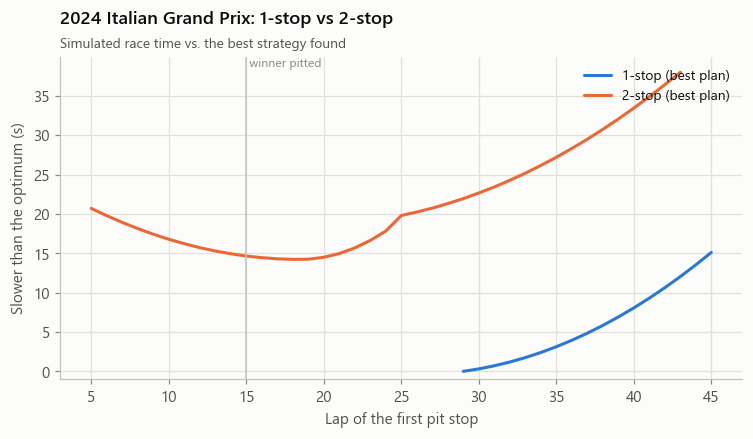

,Stops,Sequence,PitLaps,StintLengths,Gap
0,1,H-M,[29],"[29, 24]",0.0
1,2,H-H-M,"[18, 37]","[18, 19, 16]",14.2


In [4]:
EXAMPLE = (2024, "Italian Grand Prix")
row = review[(review["Season"] == EXAMPLE[0]) & (review["EventName"] == EXAMPLE[1])].iloc[0]
lp = laps.copy()
lp["RaceId"] = lp["Season"].astype(str) + "-" + lp["Round"].astype(str).str.zfill(2)
race_laps = lp[lp["RaceId"] == row["RaceId"]]
st = stints(race_laps)
model = fit_race_tyre_model(clean_laps(race_laps), max_stint=observed_max_stint(st))
plans = simulate_strategies(int(row["TotalLaps"]), model.base_lap, model.compounds,
                            float(row["PitLoss"]), model.max_stint)
winner = results[(results["Season"] == EXAMPLE[0]) & (results["EventName"] == EXAMPLE[1])
                 & (results["Position"] == 1)]["Abbreviation"].iloc[0]
winner_pits = (st[(st["Driver"] == winner) & (st["Stint"] > 1)]["StartLap"] - 1).astype(int).tolist()
fig = plots.simulator_curves(plans, f"{EXAMPLE[0]} {EXAMPLE[1]}: 1-stop vs 2-stop", winner_pits)
plots.save(fig, "simulator_curves")
plt.show()
best_by_stops(plans)[["Stops", "Sequence", "PitLaps", "StintLengths", "Gap"]].round(1)